<a href="https://colab.research.google.com/github/aarathikandregula2026/test/blob/main/AI_Home_Buying_Advisor_Combined_Result1_Result2_Mortgage_Rates.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AI Home Buying Advisor — Results 1 & 2 | Chicago + Mortgage Rates
**Northwestern MSDS Capstone · Team 2 · End-to-end Google Colab notebook**

**Data:** `chicago_sales_with_mortgage_rates.csv` (2,095 matched sales, 71 columns). Run cells top-to-bottom. Outputs are written to `Combined_Results_Outputs` beside the input CSV. This is a research prototype, **not an appraisal, financial/legal advice, or guaranteed negotiation result**.

**Critical methodology:** Mortgage rates in this CSV are aligned to the **eventual sale date**. They are useful for retrospective EDA but are **not available at listing time** and are therefore **excluded from the pre-sale valuation model** to prevent look-ahead leakage. For a genuine macroeconomic feature, obtain a historical rate series and join using an as-of date available at the buyer decision time.

## Setup: Google Drive / local testing

In [1]:
# Install if needed in Colab (uncomment):
# %pip -q install lightgbm shap streamlit openai
import os, json, re, warnings, pathlib
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.neighbors import NearestNeighbors
from sklearn.inspection import permutation_importance
from sklearn.base import clone
from lightgbm import LGBMRegressor
warnings.filterwarnings('ignore', category=FutureWarning)
DRIVE_FOLDER = Path('/content/drive/MyDrive/MSDS Capstone/Colab Notebooks')
if 'google.colab' in __import__('sys').modules or Path('/content').exists():
    try:
        from google.colab import drive
        drive.mount('/content/drive')
    except ImportError: pass
LOCAL_FILE = Path('/mnt/data/chicago_sales_with_mortgage_rates.csv')
CSV_PATH = DRIVE_FOLDER / 'chicago_sales_with_mortgage_rates.csv'
if not CSV_PATH.exists() and LOCAL_FILE.exists():
    CSV_PATH = LOCAL_FILE  # convenient for local verification
if not CSV_PATH.exists():
    raise FileNotFoundError(f'Upload chicago_sales_with_mortgage_rates.csv to {DRIVE_FOLDER} or update CSV_PATH')
OUT = CSV_PATH.parent / 'Combined_Results_Outputs'
OUT.mkdir(exist_ok=True,parents=True)
print('Input:',CSV_PATH,' | Outputs:',OUT)
def fig(name):
    plt.tight_layout();plt.savefig(OUT/name,dpi=140,bbox_inches='tight');plt.show()
def tab(frame,name):
    frame.to_csv(OUT/name,index=False);display(frame.head(20));return frame

Mounted at /content/drive
Input: /content/drive/MyDrive/MSDS Capstone/Colab Notebooks/chicago_sales_with_mortgage_rates.csv  | Outputs: /content/drive/MyDrive/MSDS Capstone/Colab Notebooks/Combined_Results_Outputs


# Result 1 — Robust Pricing Assessment
## Activity 1.1 — Data acquisition, cleaning and extensive EDA
### 1.1a Dataset schema, coverage, data lineage and market selection

In [2]:
raw = pd.read_csv(CSV_PATH,low_memory=False, dtype={'zipCode_property':'string','zipCode_listing':'string'})
print('Rows, columns:',raw.shape)
assert {'lastSalePrice','lastSaleDate','price','mortgage_30y_at_sale_pct'}.issubset(raw.columns)
display(raw.head(3));display(pd.DataFrame({'column':raw.columns,'dtype':raw.dtypes.astype(str).values,'missing_pct':raw.isna().mean().mul(100).round(2).values}))

Rows, columns: (2095, 71)


,id,formattedAddress_listing,addressLine1_listing,addressLine2_listing,city_listing,state_listing,stateFips_listing,zipCode_listing,county_listing,countyFips_listing,...,zoning,days_to_sale_after_removal,sale_to_list_ratio,discount_amount,discount_pct,mortgage_30y_at_sale_pct,mortgage_30y_observation_date,mortgage_30y_30d_prior_pct,mortgage_30y_90d_prior_pct,mortgage_30y_change_90d_pp
0,"10650-S-State-St,-Chicago,-IL-60628","10650 S State St, Chicago, IL 60628",10650 S State St,NaN,Chicago,IL,17,60628,Cook,31,...,NaN,13,0.847784,7900,0.152216,6.49,2026-06-25,6.53,6.46,0.03
1,"3855-W-31st-St,-Chicago,-IL-60623","3855 W 31st St, Chicago, IL 60623",3855 W 31st St,NaN,Chicago,IL,17,60623,Cook,31,...,NaN,23,0.958333,10000,0.041667,6.49,2026-06-25,6.53,6.38,0.11
2,"703-W-116th-St,-Chicago,-IL-60628","703 W 116th St, Chicago, IL 60628",703 W 116th St,NaN,Chicago,IL,17,60628,Cook,31,...,NaN,24,1.055505,-6100,-0.055505,6.49,2026-06-25,6.53,6.38,0.11


,column,dtype,missing_pct
0,id,object,0.0
1,formattedAddress_listing,object,0.0
2,addressLine1_listing,object,0.0
3,addressLine2_listing,float64,100.0
4,city_listing,object,0.0
...,...,...,...
66,mortgage_30y_at_sale_pct,float64,0.0
67,mortgage_30y_observation_date,object,0.0
68,mortgage_30y_30d_prior_pct,float64,0.0
69,mortgage_30y_90d_prior_pct,float64,0.0


In [3]:
d=raw.copy()
for c in ['lastSaleDate','listedDate','removedDate','mortgage_30y_observation_date']:
    if c in d:d[c]=pd.to_datetime(d[c],errors='coerce',utc=True)
num=['lastSalePrice','price','squareFootage_property','squareFootage_listing','bedrooms_property','bedrooms_listing','bathrooms_property','bathrooms_listing','yearBuilt_property','yearBuilt_listing','lotSize_property','lotSize_listing','daysOnMarket','latitude_property','longitude_property','sale_to_list_ratio','discount_amount','discount_pct','mortgage_30y_at_sale_pct','mortgage_30y_30d_prior_pct','mortgage_30y_90d_prior_pct','mortgage_30y_change_90d_pp','days_to_sale_after_removal']
for c in num:
    if c in d:d[c]=pd.to_numeric(d[c],errors='coerce')
for c in ['zipCode_property','zipCode_listing']:
    d[c]=d[c].astype('string').str.extract(r'(\d{5})',expand=False)
market=pd.DataFrame([{'records':len(d),'sale_date_min':d.lastSaleDate.min(),'sale_date_max':d.lastSaleDate.max(),'unique_zips':d.zipCode_property.nunique(),'chicago_share':d.city_property.astype(str).str.lower().eq('chicago').mean(),'single_family_share':d.propertyType_property.astype(str).str.lower().str.contains('single').mean()}])
tab(market,'market_feasibility.csv')
print('MVP decision: Chicago single-family homes; sparse ZIPs need explicit coverage caveats.')

,records,sale_date_min,sale_date_max,unique_zips,chicago_share,single_family_share
0,2095,2025-05-05 00:00:00+00:00,2026-07-02 00:00:00+00:00,48,1.0,1.0


MVP decision: Chicago single-family homes; sparse ZIPs need explicit coverage caveats.


### 1.1b Data-quality audit — missingness, duplicates, inconsistent square footage, dates, outliers, and match plausibility

,column,missing_pct
0,addressLine2_listing,100.000000
1,zoning,100.000000
2,addressLine2_property,100.000000
3,hoa_listing,99.379475
4,hoa_property,99.379475
5,lotSize_listing,37.899761
6,squareFootage_listing,8.830549
7,subdivision,7.541766
8,yearBuilt_listing,4.916468
9,propertyTaxes,0.906921


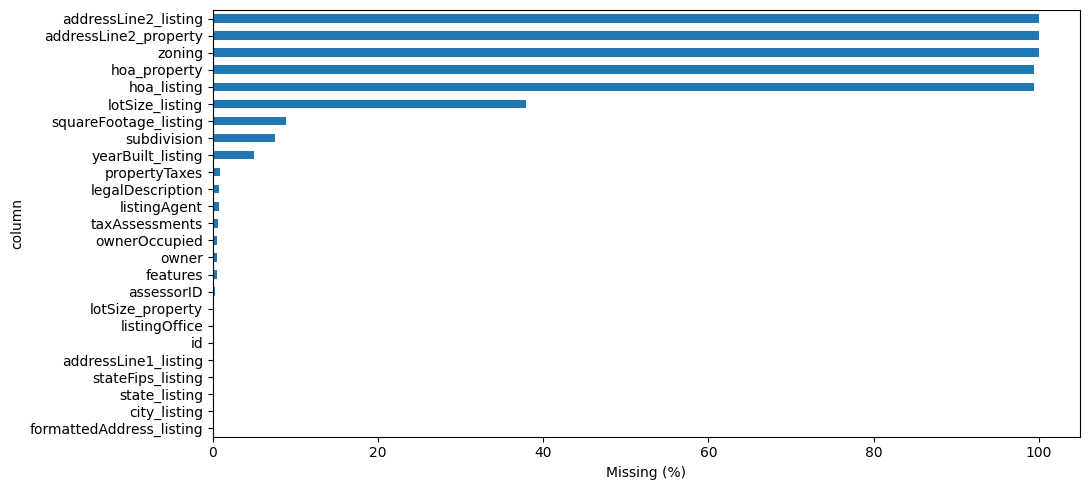

Duplicate property IDs: 0 Duplicate full rows: 0


In [4]:
miss=(d.isna().mean()*100).sort_values(ascending=False).rename('missing_pct').reset_index().rename(columns={'index':'column'})
tab(miss,'missingness.csv')
plt.figure(figsize=(11,5));miss.head(25).sort_values('missing_pct').plot.barh(x='column',y='missing_pct',legend=False,ax=plt.gca());plt.xlabel('Missing (%)');fig('missingness.png')
print('Duplicate property IDs:',d.id.duplicated().sum(),'Duplicate full rows:',d.duplicated().sum())

Both sources available: 1910 Disagreements: 1108 Listing sqft missing: 185
HOA listing missing %: 99.4 Property HOA missing %: 99.4


,id,squareFootage_property,squareFootage_listing,sqft_abs_difference
0,"10650-S-State-St,-Chicago,-IL-60628",880,1200.0,320.0
1,"3855-W-31st-St,-Chicago,-IL-60623",1225,2800.0,1575.0
3,"6122-N-Newburg-Ave,-Chicago,-IL-60631",1479,2977.0,1498.0
11,"8115-S-Troy-St,-Chicago,-IL-60652",1005,1475.0,470.0
12,"2330-N-Kildare-Ave,-Chicago,-IL-60639",1644,2200.0,556.0
15,"3416-N-Oriole-Ave,-Chicago,-IL-60634",1056,2000.0,944.0
16,"3927-N-Paulina-St,-Chicago,-IL-60613",2200,3185.0,985.0
17,"4330-N-Avers-Ave,-Chicago,-IL-60618",900,1600.0,700.0
18,"11151-S-Christiana-Ave,-Chicago,-IL-60655",864,1517.0,653.0
19,"4105-N-Kolmar-Ave,-Chicago,-IL-60641",912,1600.0,688.0


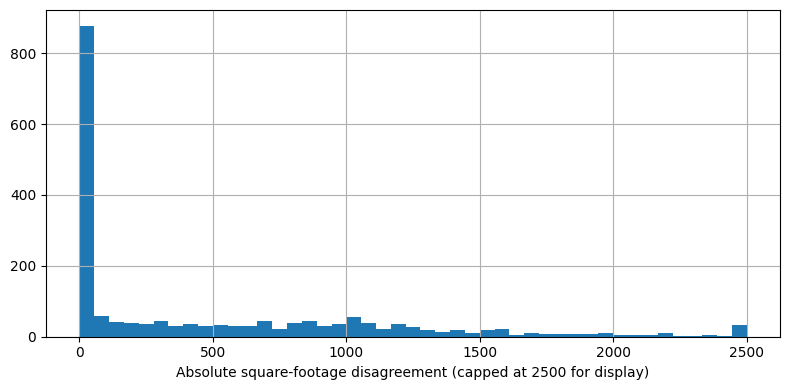

In [5]:
both=d[['squareFootage_property','squareFootage_listing']].notna().all(axis=1)
d['sqft_disagreement']=both & d.squareFootage_property.ne(d.squareFootage_listing)
d['sqft_abs_difference']=(d.squareFootage_property-d.squareFootage_listing).abs().where(both)
print('Both sources available:',both.sum(),'Disagreements:',d.sqft_disagreement.sum(),'Listing sqft missing:',d.squareFootage_listing.isna().sum())
print('HOA listing missing %:',round(d.hoa_listing.isna().mean()*100,1),'Property HOA missing %:',round(d.hoa_property.isna().mean()*100,1))
display(d.loc[d.sqft_disagreement,['id','squareFootage_property','squareFootage_listing','sqft_abs_difference']].head(10))
plt.figure(figsize=(8,4));d.sqft_abs_difference.dropna().clip(upper=2500).hist(bins=45);plt.xlabel('Absolute square-footage disagreement (capped at 2500 for display)');fig('sqft_disagreements.png')

In [6]:
# Cleaning is non-destructive: preserve raw data; record every removal.
audit=[]
def filter_rows(label,condition):
    global d
    before=len(d);d=d.loc[condition.fillna(False)].copy();audit.append({'step':label,'before':before,'removed':before-len(d),'remaining':len(d)})
filter_rows('Unique property IDs',~d.id.duplicated(keep='first'))
filter_rows('Valid recorded sale and date',d.lastSalePrice.gt(10000)&d.lastSaleDate.notna())
filter_rows('Plausible Chicago ZIP and price',d.zipCode_property.str.match(r'^606\d{2}$|^607\d{2}$|^608\d{2}$',na=False)&d.lastSalePrice.between(10000,20000000))
filter_rows('Plausible property size when provided',d.squareFootage_property.isna()|d.squareFootage_property.between(250,20000))
filter_rows('Plausible beds/baths when provided',(d.bedrooms_property.isna()|d.bedrooms_property.between(0,20))&(d.bathrooms_property.isna()|d.bathrooms_property.between(0,20)))
tab(pd.DataFrame(audit),'cleaning_audit.csv')
# Explicit precedence; conflicts are flagged, not magically reconciled.
d['sqft_model']=d.squareFootage_property.combine_first(d.squareFootage_listing)
d['beds_model']=d.bedrooms_property.combine_first(d.bedrooms_listing)
d['baths_model']=d.bathrooms_property.combine_first(d.bathrooms_listing)
d['year_model']=d.yearBuilt_property.combine_first(d.yearBuilt_listing)
d['lot_model']=d.lotSize_property.combine_first(d.lotSize_listing)
d['zip_model']=d.zipCode_property.fillna(d.zipCode_listing).astype(str)
d['latitude_model']=d.latitude_property.combine_first(d.latitude_listing)
d['longitude_model']=d.longitude_property.combine_first(d.longitude_listing)
d['age_at_sale']=d.lastSaleDate.dt.year-d.year_model
# IMPORTANT: sale date is not used as a numeric predictor; only for chronological splitting.

,step,before,removed,remaining
0,Unique property IDs,2095,0,2095
1,Valid recorded sale and date,2095,0,2095
2,Plausible Chicago ZIP and price,2095,0,2095
3,Plausible property size when provided,2095,0,2095
4,Plausible beds/baths when provided,2095,0,2095


In [7]:
match=pd.DataFrame({'check':['Sale 0–60 days after listing removal','Same listing/property ZIP','Same listing/property street address','Valid asking price','Recorded sale-to-ask ratio 0.5–1.5'],
'pass_count':[(d.lastSaleDate.sub(d.removedDate).dt.days.between(0,60)).sum(),(d.zipCode_listing==d.zipCode_property).sum(),(d.addressLine1_listing.astype(str).str.upper().str.strip()==d.addressLine1_property.astype(str).str.upper().str.strip()).sum(),d.price.gt(0).sum(),d.lastSalePrice.div(d.price.replace(0,np.nan)).between(.5,1.5).sum()]})
match['share']=match.pass_count/len(d);tab(match,'matching_plausibility.csv')
print('These are plausibility checks, NOT independent confirmation of arm’s-length transactions.')

,check,pass_count,share
0,Sale 0–60 days after listing removal,2095,1.0
1,Same listing/property ZIP,2095,1.0
2,Same listing/property street address,2095,1.0
3,Valid asking price,2095,1.0
4,Recorded sale-to-ask ratio 0.5–1.5,2095,1.0


These are plausibility checks, NOT independent confirmation of arm’s-length transactions.


### 1.1c Price, property features, geography, sales vs recorded ask, mortgage macro trends

,count,mean,std,min,10%,25%,50%,75%,90%,max
lastSalePrice,2095.0,467708.768496,445788.782360,21000.0,165000.0,258500.0,355000.0,510000.0,815400.0,5150000.0
price,2095.0,468133.421957,459913.142907,30300.0,169000.0,258000.0,350000.0,499900.0,799999.6,6900000.0
daysOnMarket,2095.0,45.826730,34.164010,1.0,7.0,21.0,41.0,61.0,90.0,264.0
sqft_model,2095.0,1352.501671,582.594071,400.0,876.0,1008.0,1176.0,1528.0,2063.2,7310.0
beds_model,2095.0,3.070644,0.850177,1.0,2.0,3.0,3.0,3.0,4.0,8.0
baths_model,2095.0,1.466826,0.737987,1.0,1.0,1.0,1.0,1.5,2.5,6.0
year_model,2095.0,1936.312649,30.078298,1861.0,1898.0,1916.0,1938.0,1953.0,1967.6,2026.0
lot_model,2094.0,4141.293696,1361.894196,900.0,3050.0,3150.0,3780.0,4650.0,5535.0,19600.0


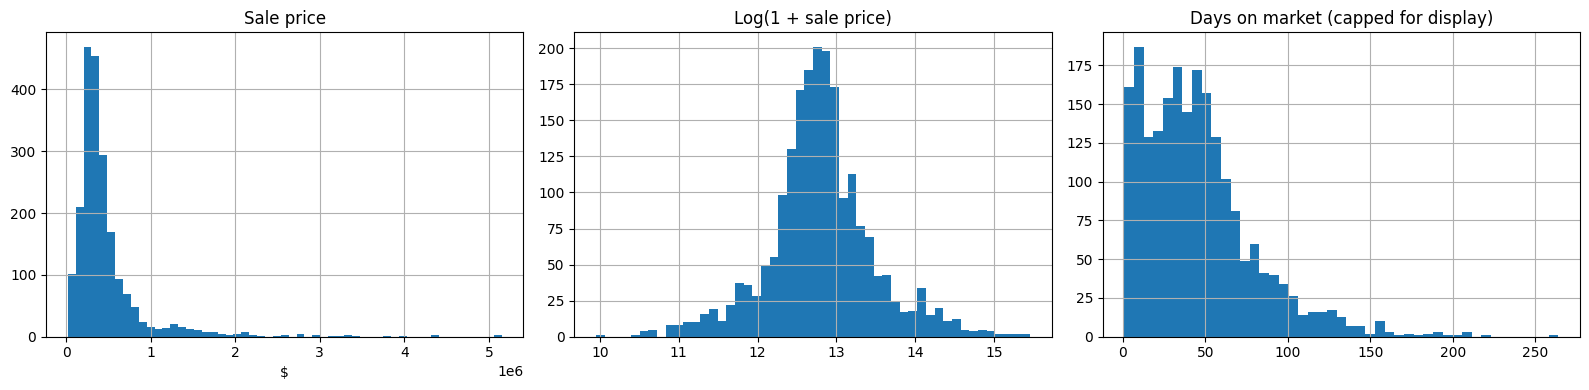

In [8]:
stats=d[['lastSalePrice','price','daysOnMarket','sqft_model','beds_model','baths_model','year_model','lot_model']].describe(percentiles=[.1,.25,.5,.75,.9]).T
stats.to_csv(OUT/'descriptive_statistics.csv');display(stats)
fig0,axes=plt.subplots(1,3,figsize=(16,4))
d.lastSalePrice.hist(bins=55,ax=axes[0]);axes[0].set_title('Sale price');axes[0].set_xlabel('$')
np.log1p(d.lastSalePrice).hist(bins=50,ax=axes[1]);axes[1].set_title('Log(1 + sale price)')
d.daysOnMarket.dropna().clip(upper=365).hist(bins=45,ax=axes[2]);axes[2].set_title('Days on market (capped for display)')
fig('price_dom_distributions.png')

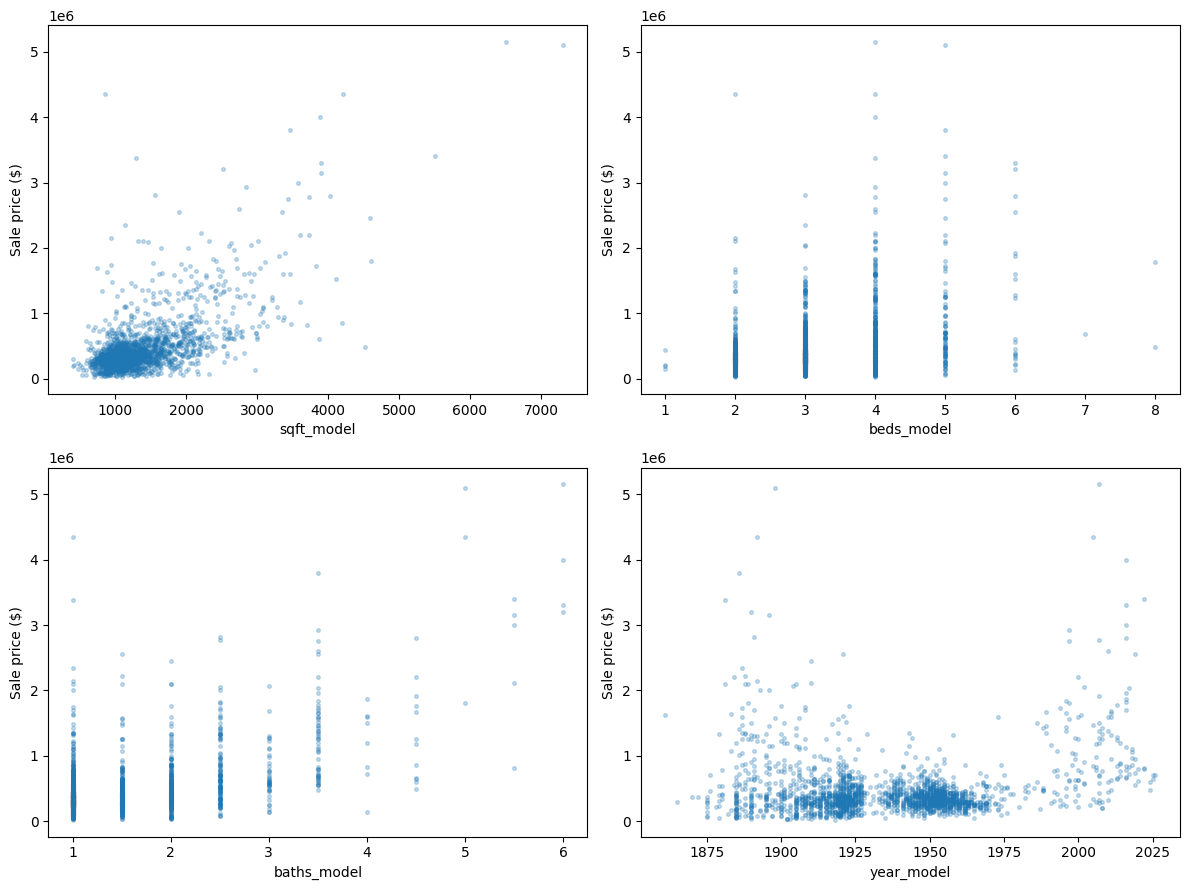

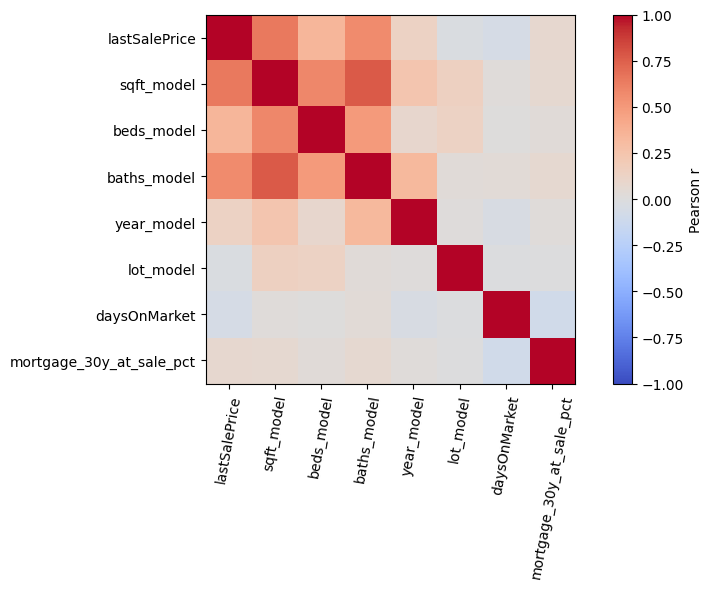

In [9]:
fig0,axes=plt.subplots(2,2,figsize=(12,9))
for ax,c in zip(axes.flat,['sqft_model','beds_model','baths_model','year_model']):
    ax.scatter(d[c],d.lastSalePrice,s=7,alpha=.25);ax.set(xlabel=c,ylabel='Sale price ($)')
fig('property_scatterplots.png')
corr=d[['lastSalePrice','sqft_model','beds_model','baths_model','year_model','lot_model','daysOnMarket','mortgage_30y_at_sale_pct']].corr(numeric_only=True)
plt.figure(figsize=(9,6));plt.imshow(corr,cmap='coolwarm',vmin=-1,vmax=1);plt.xticks(range(len(corr)),corr.columns,rotation=80);plt.yticks(range(len(corr)),corr.columns);plt.colorbar(label='Pearson r');fig('correlation_heatmap.png')

,zip_model,n,median_sale,median_dom
0,60634,150,415500.0,38.5
1,60628,146,214000.0,46.0
2,60643,117,269000.0,39.0
3,60638,115,370000.0,37.0
4,60617,102,220000.0,54.0
5,60620,97,250000.0,47.0
6,60629,93,300000.0,42.0
7,60655,82,350500.0,36.0
8,60630,81,496000.0,35.0
9,60631,81,515000.0,35.0


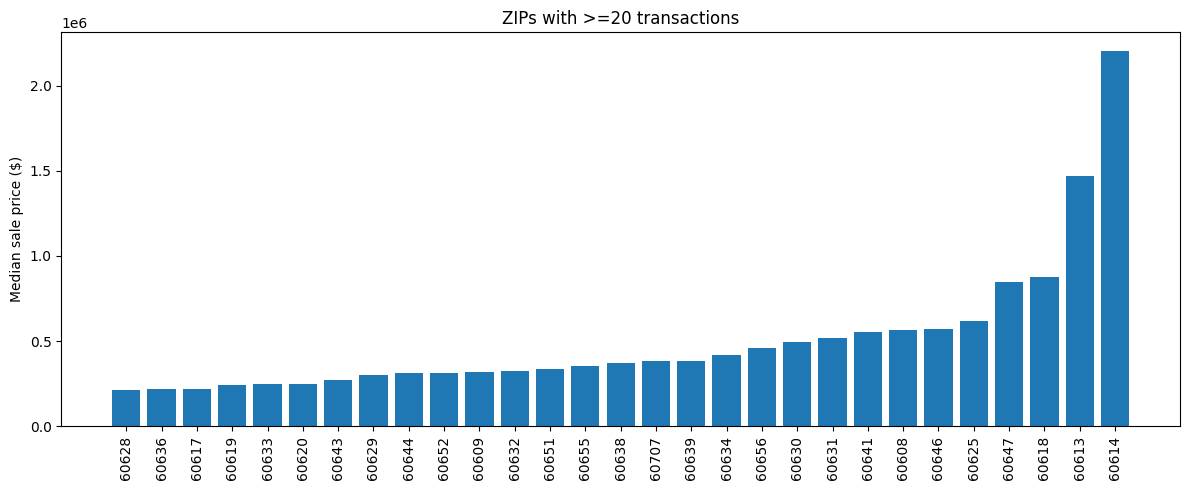

In [10]:
zip_stats=d.groupby('zip_model').agg(n=('lastSalePrice','size'),median_sale=('lastSalePrice','median'),median_dom=('daysOnMarket','median')).sort_values('n',ascending=False).reset_index()
tab(zip_stats,'zip_coverage.csv')
plt.figure(figsize=(12,5));sub=zip_stats.query('n>=20').sort_values('median_sale');plt.bar(sub.zip_model,sub.median_sale);plt.xticks(rotation=90);plt.ylabel('Median sale price ($)');plt.title('ZIPs with >=20 transactions');fig('zip_medians.png')

,outcome,count,percent
0,Below recorded ask,883,42.1
1,At recorded ask,260,12.4
2,Above recorded ask,952,45.4


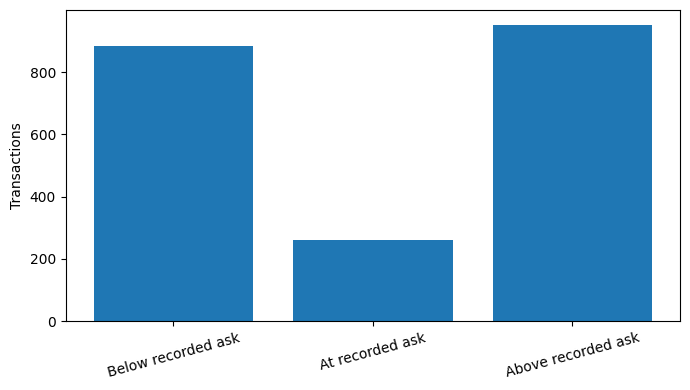

The recorded ask may already reflect price reductions. This is NOT proof of negotiated discounts.


In [11]:
ask=d[d.price.gt(0)].copy();ask['ask_outcome']=np.select([ask.lastSalePrice.lt(ask.price),ask.lastSalePrice.eq(ask.price)],['Below recorded ask','At recorded ask'],default='Above recorded ask')
ask_counts=ask.ask_outcome.value_counts().reindex(['Below recorded ask','At recorded ask','Above recorded ask']).rename_axis('outcome').reset_index(name='count');ask_counts['percent']=(ask_counts['count']/len(ask)*100).round(1)
tab(ask_counts,'sale_vs_recorded_ask.csv')
plt.figure(figsize=(7,4));plt.bar(ask_counts.outcome,ask_counts['count']);plt.xticks(rotation=15);plt.ylabel('Transactions');fig('sale_vs_asking.png')
print('The recorded ask may already reflect price reductions. This is NOT proof of negotiated discounts.')

/tmp/ipykernel_1920/1615475027.py:1: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  d['sale_month']=d.lastSaleDate.dt.to_period('M').astype(str)


,sale_month,n,median_sale,median_sqft,median_mortgage_rate
0,2025-05,41,375000.0,1119.0,6.86
1,2025-06,139,379000.0,1194.0,6.84
2,2025-07,206,375000.0,1166.5,6.74
3,2025-08,173,370000.0,1222.0,6.58
4,2025-09,230,381500.0,1186.5,6.35
5,2025-10,209,350000.0,1144.0,6.27
6,2025-11,151,340000.0,1168.0,6.23
7,2025-12,195,330000.0,1203.0,6.21
8,2026-01,139,303000.0,1191.0,6.15
9,2026-02,115,352000.0,1120.0,6.09


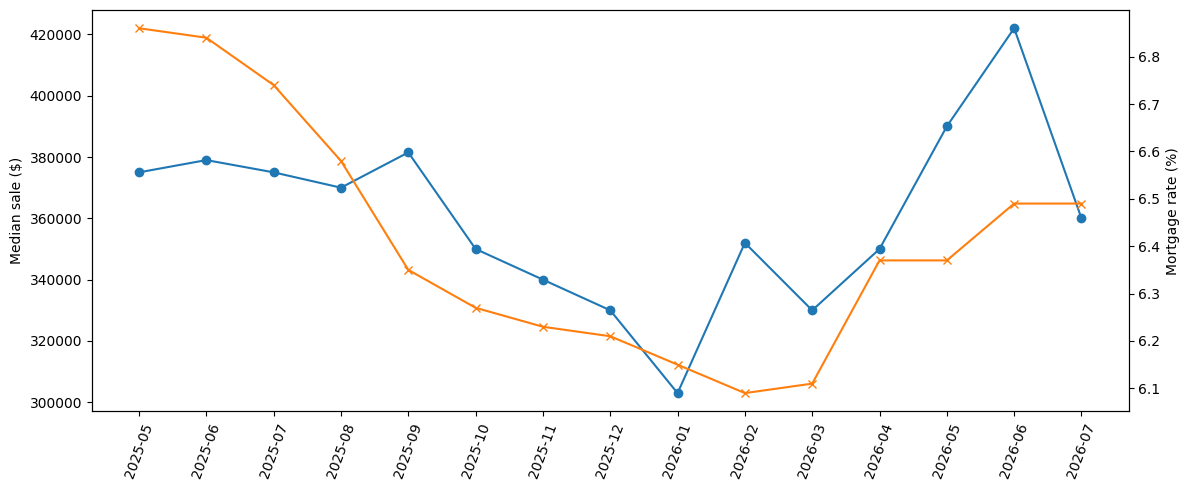

Descriptive overlay only: changes in property mix, sample size, and confounding prevent causal claims.


In [12]:
d['sale_month']=d.lastSaleDate.dt.to_period('M').astype(str)
monthly=d.groupby('sale_month').agg(n=('lastSalePrice','size'),median_sale=('lastSalePrice','median'),median_sqft=('sqft_model','median'),median_mortgage_rate=('mortgage_30y_at_sale_pct','median')).reset_index()
tab(monthly,'monthly_market_and_mortgage_trends.csv')
fig0,ax=plt.subplots(figsize=(12,5));ax.plot(monthly.sale_month,monthly.median_sale,marker='o',label='Median sale ($)');ax.set_ylabel('Median sale ($)');ax.tick_params(axis='x',rotation=70);ax2=ax.twinx();ax2.plot(monthly.sale_month,monthly.median_mortgage_rate,color='tab:orange',marker='x',label='30y mortgage rate at sale (%)');ax2.set_ylabel('Mortgage rate (%)');fig('monthly_sale_and_mortgage.png')
print('Descriptive overlay only: changes in property mix, sample size, and confounding prevent causal claims.')

In [13]:
rate_cols=['mortgage_30y_at_sale_pct','mortgage_30y_30d_prior_pct','mortgage_30y_90d_prior_pct','mortgage_30y_change_90d_pp']
display(d[rate_cols].describe().T)
print('IMPORTANT: rate features are sale-date-aligned, not buyer decision-date aligned. They are EXCLUDED from predictive features to avoid future information leakage.')

,count,mean,std,min,25%,50%,75%,max
mortgage_30y_at_sale_pct,2095.0,6.388955,0.242343,5.98,6.21,6.34,6.58,6.89
mortgage_30y_30d_prior_pct,2095.0,6.431179,0.268228,5.98,6.22,6.36,6.72,6.89
mortgage_30y_90d_prior_pct,2095.0,6.502840,0.281353,5.98,6.22,6.58,6.76,6.95
mortgage_30y_change_90d_pp,2095.0,-0.113885,0.269298,-0.55,-0.33,-0.13,0.12,0.55


IMPORTANT: rate features are sale-date-aligned, not buyer decision-date aligned. They are EXCLUDED from predictive features to avoid future information leakage.


## Activity 1.2 — Four-model comparison and nearest-neighbor comparable sales
**Four models:** train-median dummy, ordinary linear regression, Ridge regression, LightGBM. Time-aware split (60/20/20), validation selection, untouched test evaluation. Missing data handled in pipelines. Sale outcome, recorded ask, and sale-aligned mortgage features are excluded from predictors.

In [14]:
d=d.sort_values('lastSaleDate',kind='stable').reset_index(drop=True)
N=len(d);ntrain=int(.60*N);nval=int(.20*N)
train=d.iloc[:ntrain].copy();val=d.iloc[ntrain:ntrain+nval].copy();test=d.iloc[ntrain+nval:].copy()
for name,part in [('train',train),('validation',val),('test',test)]:print(name,len(part),part.lastSaleDate.min().date(),part.lastSaleDate.max().date())
features_num=['sqft_model','beds_model','baths_model','year_model','lot_model','latitude_model','longitude_model']
features_cat=['zip_model']
features=features_num+features_cat
yname='lastSalePrice'
try:oh=OneHotEncoder(handle_unknown='ignore',sparse_output=False)
except TypeError:oh=OneHotEncoder(handle_unknown='ignore',sparse=False)
pre=ColumnTransformer([('num',Pipeline([('imputer',SimpleImputer(strategy='median',add_indicator=False)),('scale',StandardScaler())]),features_num),('cat',Pipeline([('imputer',SimpleImputer(strategy='most_frequent')),('onehot',oh)]),features_cat)])
models={'Median baseline':DummyRegressor(strategy='median'),'Linear Regression':LinearRegression(),'Ridge Regression':Ridge(alpha=20),'LightGBM':LGBMRegressor(n_estimators=250,learning_rate=.04,num_leaves=15,max_depth=5,min_child_samples=20,random_state=42,verbosity=-1)}
def metrics(y,p):
    y=np.asarray(y,dtype=float);p=np.asarray(p,dtype=float)
    return {'MAE':mean_absolute_error(y,p),'RMSE':np.sqrt(mean_squared_error(y,p)),'MdAPE_pct':np.median(np.abs((y-p)/np.maximum(np.abs(y),1)))*100}
fits={};records=[]
for name,model in models.items():
    pipe=Pipeline([('preprocess',clone(pre)),('model',clone(model))]);pipe.fit(train[features],train[yname]);fits[name]=pipe
    for split_name,part in [('train',train),('validation',val)]:records.append({'model':name,'split':split_name,**metrics(part[yname],pipe.predict(part[features]))})
comparison=pd.DataFrame(records);tab(comparison,'model_comparison_train_validation.csv')
selected_name=comparison[comparison.split.eq('validation')].sort_values('MdAPE_pct').iloc[0]['model'];print('Selected using validation MdAPE:',selected_name)

train 1257 2025-05-05 2025-12-16
validation 419 2025-12-16 2026-03-18
test 419 2026-03-19 2026-07-02


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


,model,split,MAE,RMSE,MdAPE_pct
0,Median baseline,train,241400.214797,494421.117376,33.828996
1,Median baseline,validation,188255.369928,348994.753125,33.023256
2,Linear Regression,train,127718.763056,221506.361563,22.122150
3,Linear Regression,validation,126822.198948,201332.987178,24.664416
4,Ridge Regression,train,148452.048406,253720.162600,25.800706
5,Ridge Regression,validation,141386.991910,221735.851345,27.893984
6,LightGBM,train,91257.856689,156894.128482,15.634821
7,LightGBM,validation,111778.171299,191683.430139,20.912284


Selected using validation MdAPE: LightGBM


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


,model,split,MAE,RMSE,MdAPE_pct
0,LightGBM,held-out test,124519.812119,230807.496197,20.042218


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


,model,MAE,RMSE,MdAPE_pct
0,Median baseline,224975.178998,445209.560911,33.649289
1,Linear Regression,136397.788242,247852.101263,24.393575
2,Ridge Regression,157588.294252,282715.954360,27.095779
3,LightGBM,124519.812119,230807.496197,20.042218


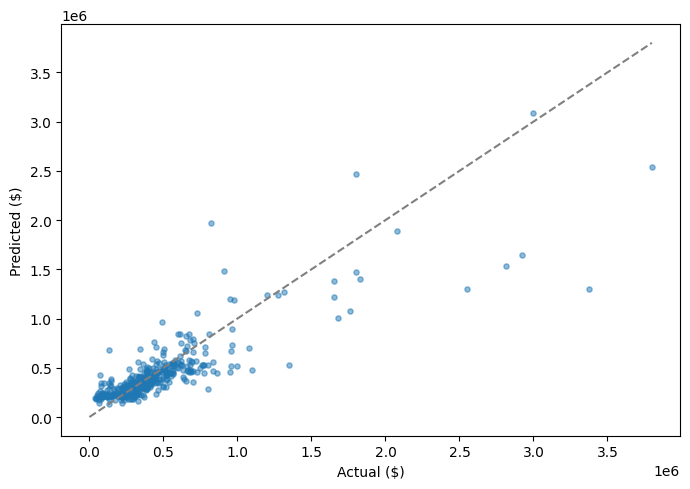

In [15]:
# Refit only on train + validation after selection, then evaluate test ONCE.
trainval=pd.concat([train,val],ignore_index=True)
final_model=Pipeline([('preprocess',clone(pre)),('model',clone(models[selected_name]))]);final_model.fit(trainval[features],trainval[yname])
test_pred=final_model.predict(test[features]);test_metrics=pd.DataFrame([{'model':selected_name,'split':'held-out test',**metrics(test[yname],test_pred)}]);tab(test_metrics,'heldout_test_metrics.csv')
all_model_test=[]
for name,est in models.items():
    pipe=Pipeline([('preprocess',clone(pre)),('model',clone(est))]);pipe.fit(trainval[features],trainval[yname]);all_model_test.append({'model':name,**metrics(test[yname],pipe.predict(test[features]))})
tab(pd.DataFrame(all_model_test),'four_model_test_comparison.csv')
plt.figure(figsize=(7,5));plt.scatter(test[yname],test_pred,alpha=.5,s=14);mx=max(test[yname].max(),np.max(test_pred));plt.plot([0,mx],[0,mx],'--',color='gray');plt.xlabel('Actual ($)');plt.ylabel('Predicted ($)');fig('test_actual_vs_predicted.png')

In [16]:
hold=test[['zip_model','lastSalePrice']].copy();hold['predicted']=test_pred;hold['abs_error']=(hold.lastSalePrice-hold.predicted).abs();hold['APE_pct']=hold.abs_error/hold.lastSalePrice.clip(lower=1)*100
zip_err=hold.groupby('zip_model').agg(n=('abs_error','size'),MAE=('abs_error','mean'),MdAPE_pct=('APE_pct','median')).reset_index().sort_values('n',ascending=False)
tab(zip_err,'test_zip_error.csv')
hold['price_band']=pd.qcut(hold.lastSalePrice,4,duplicates='drop')
price_err=hold.groupby('price_band',observed=True).agg(n=('abs_error','size'),MAE=('abs_error','mean'),MdAPE_pct=('APE_pct','median')).reset_index();price_err['price_band']=price_err.price_band.astype(str)
tab(price_err,'test_price_band_error.csv')
print('Small ZIP samples cannot establish reliable segment-level accuracy.')

,zip_model,n,MAE,MdAPE_pct
19,60634,38,91746.175883,15.259667
22,60638,28,70823.265907,14.991908
13,60628,27,106396.166563,46.447861
5,60617,25,60711.424444,20.975352
25,60643,24,79820.553711,17.471099
15,60630,23,124947.209363,16.383473
8,60620,18,88597.336621,30.329926
34,60655,18,88661.162491,21.047453
7,60619,16,87569.804932,35.596312
28,60646,16,96762.068907,8.108360


,price_band,n,MAE,MdAPE_pct
0,"(38999.999, 255000.0]",107,94334.336632,46.453541
1,"(255000.0, 380000.0]",106,64099.499458,17.091753
2,"(380000.0, 521000.0]",101,71965.839694,14.031630
3,"(521000.0, 3800000.0]",105,266827.909587,22.624076


Small ZIP samples cannot establish reliable segment-level accuracy.


### Comparable sales: nearest neighbors from historical properties only
The candidate pool must predate the evaluated sale. For a demo listing, the pool is limited to recorded earlier sales. Distances use scaled size, beds, baths, coordinates and a same-ZIP preference. Comparable records are *examples*, not verified appraisal comps.

In [17]:
from sklearn.preprocessing import RobustScaler
comp_cols=['sqft_model','beds_model','baths_model','latitude_model','longitude_model']
def get_comps(subject, history, k=5, max_age_days=365):
    asof=pd.to_datetime(subject['lastSaleDate'],utc=True)
    pool=history.loc[(history.lastSaleDate<asof)&(history.lastSaleDate>=asof-pd.Timedelta(days=max_age_days))].copy()
    if len(pool)<k:pool=history.loc[history.lastSaleDate<asof].copy()
    if pool.empty:return pd.DataFrame()
    # Prefer same ZIP; broaden only if insufficient examples.
    same=pool.loc[pool.zip_model==str(subject['zip_model'])]
    if len(same)>=k:pool=same
    med=pool[comp_cols].median(numeric_only=True).fillna(0)
    a=pool[comp_cols].fillna(med);b=pd.DataFrame([subject])[comp_cols].fillna(med)
    scaler=RobustScaler().fit(a);xa=scaler.transform(a);xb=scaler.transform(b)
    zip_penalty=(pool.zip_model!=str(subject['zip_model'])).astype(float).to_numpy()*3
    dist=np.sqrt(((xa-xb)**2).sum(axis=1))+zip_penalty
    pool=pool.assign(distance=dist).sort_values('distance').head(k)
    return pool[['id','formattedAddress_property','zip_model','lastSaleDate','lastSalePrice','sqft_model','beds_model','baths_model','distance']]
example=test.iloc[0];comps=get_comps(example,trainval,k=5);tab(comps,'example_comparable_sales.csv')

,id,formattedAddress_property,zip_model,lastSaleDate,lastSalePrice,sqft_model,beds_model,baths_model,distance
383,"4406-W-Augusta-Blvd,-Chicago,-IL-60651","4406 W Augusta Blvd, Chicago, IL 60651",60651,2025-07-31 00:00:00+00:00,285000,924,2,1.0,0.875610
1566,"841-N-Kildare-Ave,-Chicago,-IL-60651","841 N Kildare Ave, Chicago, IL 60651",60651,2026-02-23 00:00:00+00:00,237000,999,2,1.0,1.068609
30,"1240-N-Parkside-Ave,-Chicago,-IL-60651","1240 N Parkside Ave, Chicago, IL 60651",60651,2025-05-28 00:00:00+00:00,375000,1119,3,1.0,1.105403
165,"1310-N-Mayfield-Ave,-Chicago,-IL-60651","1310 N Mayfield Ave, Chicago, IL 60651",60651,2025-06-26 00:00:00+00:00,400000,1178,3,1.0,1.166413
258,"1401-N-Keeler-Ave,-Chicago,-IL-60651","1401 N Keeler Ave, Chicago, IL 60651",60651,2025-07-14 00:00:00+00:00,357000,869,2,1.0,1.174008


,id,formattedAddress_property,zip_model,lastSaleDate,lastSalePrice,sqft_model,beds_model,baths_model,distance
383,"4406-W-Augusta-Blvd,-Chicago,-IL-60651","4406 W Augusta Blvd, Chicago, IL 60651",60651,2025-07-31 00:00:00+00:00,285000,924,2,1.0,0.875610
1566,"841-N-Kildare-Ave,-Chicago,-IL-60651","841 N Kildare Ave, Chicago, IL 60651",60651,2026-02-23 00:00:00+00:00,237000,999,2,1.0,1.068609
30,"1240-N-Parkside-Ave,-Chicago,-IL-60651","1240 N Parkside Ave, Chicago, IL 60651",60651,2025-05-28 00:00:00+00:00,375000,1119,3,1.0,1.105403
165,"1310-N-Mayfield-Ave,-Chicago,-IL-60651","1310 N Mayfield Ave, Chicago, IL 60651",60651,2025-06-26 00:00:00+00:00,400000,1178,3,1.0,1.166413
258,"1401-N-Keeler-Ave,-Chicago,-IL-60651","1401 N Keeler Ave, Chicago, IL 60651",60651,2025-07-14 00:00:00+00:00,357000,869,2,1.0,1.174008


## Activity 1.3 — Explainability, leverage signals, and uncertainty

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/v

,feature,MAE_increase_when_shuffled
5,latitude_model,198742.112840
6,longitude_model,116270.246533
0,sqft_model,19199.949708
7,zip_model,9732.869856
4,lot_model,3621.137181
3,year_model,3259.102594
2,baths_model,2870.961956
1,beds_model,51.857745


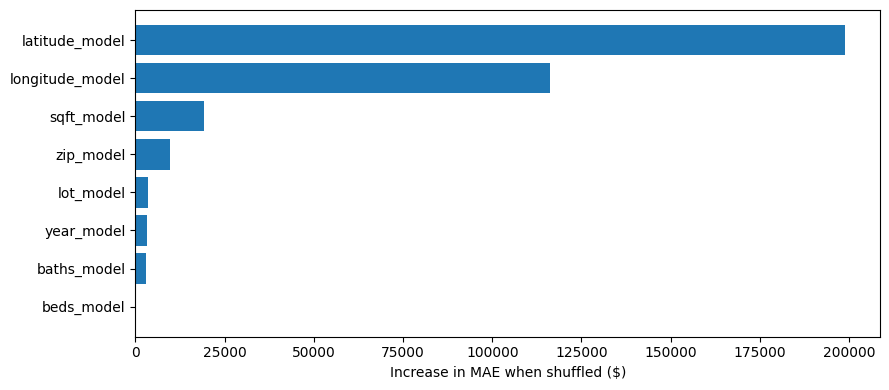

Permutation importance is a model explanation, not a causal effect.


In [18]:
# Permutation importance operates on original input columns, so it works for all four models.
imp=permutation_importance(final_model,test[features],test[yname],n_repeats=5,random_state=42,scoring='neg_mean_absolute_error')
importance=pd.DataFrame({'feature':features,'MAE_increase_when_shuffled':imp.importances_mean}).sort_values('MAE_increase_when_shuffled',ascending=False)
tab(importance,'permutation_feature_importance.csv')
plt.figure(figsize=(9,4));plt.barh(importance.feature[::-1],importance.MAE_increase_when_shuffled[::-1]);plt.xlabel('Increase in MAE when shuffled ($)');fig('feature_importance.png')
print('Permutation importance is a model explanation, not a causal effect.')

In [19]:
# Calibration: holdout coverage of a range sized using validation residuals from train-only fit.
val_pred=fits[selected_name].predict(val[features]);abs_val_err=np.abs(val[yname].to_numpy()-val_pred)
q80=float(np.quantile(abs_val_err,np.ceil((len(abs_val_err)+1)*.80)/len(abs_val_err),method='higher')) if np.ceil((len(abs_val_err)+1)*.80)/len(abs_val_err)<=1 else float(abs_val_err.max())
lo=np.maximum(0,test_pred-q80);hi=test_pred+q80
coverage=np.mean((test[yname].to_numpy()>=lo)&(test[yname].to_numpy()<=hi))
tab(pd.DataFrame([{'nominal_coverage':.80,'observed_test_coverage':coverage,'validation_abs_error_radius':q80,'test_n':len(test)}]),'uncertainty_coverage.csv')
print('Approximate symmetric residual interval; no guarantee of coverage for a specific ZIP/price band.')

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


,nominal_coverage,observed_test_coverage,validation_abs_error_radius,test_n
0,0.8,0.76611,139543.956089,419


Approximate symmetric residual interval; no guarantee of coverage for a specific ZIP/price band.


In [20]:
# Descriptive leverage signals; use prior history only for local sale-to-recorded-ask.
def buyer_signals(subject, estimate, radius, history):
    ask=float(subject.get('price',np.nan));dom=float(subject.get('daysOnMarket',np.nan))
    prior=history.loc[(history.lastSaleDate<pd.to_datetime(subject['lastSaleDate'],utc=True))&(history.zip_model==str(subject['zip_model']))&history.price.gt(0)]
    local_ratio=prior.lastSalePrice.div(prior.price).median() if len(prior)>=5 else np.nan
    gap=ask-estimate if np.isfinite(ask) else np.nan
    return {'estimated_value':round(float(estimate)),'range_low':round(max(0,estimate-radius)),'range_high':round(estimate+radius),'recorded_ask':round(ask) if np.isfinite(ask) else None,'ask_minus_estimate':round(gap) if np.isfinite(gap) else None,'days_on_market':round(dom) if np.isfinite(dom) else None,'historical_local_sale_to_recorded_ask_median':round(float(local_ratio),3) if np.isfinite(local_ratio) else None,'historical_local_count':int(len(prior)),'price_cut_history_verified':False}
subject=test.iloc[0];signals=buyer_signals(subject,float(test_pred[0]),q80,trainval)
print(json.dumps(signals,indent=2));(OUT/'example_signals.json').write_text(json.dumps(signals,indent=2))

{
  "estimated_value": 321064,
  "range_low": 181520,
  "range_high": 460608,
  "recorded_ask": 135000,
  "ask_minus_estimate": -186064,
  "days_on_market": 7,
  "historical_local_sale_to_recorded_ask_median": 0.992,
  "historical_local_count": 32,
  "price_cut_history_verified": false
}


288

# Result 2 — Buyer-facing AI negotiation prototype and evaluation
## Activity 2.1 — Rule-based negotiation logic (no success prediction)
We lack verified original ask and offer/acceptance outcomes. **Do not train a negotiation-success classifier or infer price-cut history from the recorded ask.**

In [21]:
def negotiation_points(s):
    points=[];gap=s.get('ask_minus_estimate');ask=s.get('recorded_ask')
    if gap is not None and ask and gap>0.05*ask:points.append('Recorded asking price is more than 5% above the model estimate; ask for the seller’s pricing rationale.')
    elif gap is not None and ask and gap < -0.05*ask:points.append('Recorded asking price is more than 5% below the model estimate; investigate condition and other risks.')
    else:points.append('Recorded asking price is near the model estimate; verify comparable sales and property condition.')
    if s.get('days_on_market') is not None and s['days_on_market']>=60:points.append('Longer observed days on market may justify asking about seller timing, but does not guarantee flexibility.')
    if s.get('historical_local_count',0)>=5:points.append('Review local historical sale-to-recorded-ask patterns; these are not confirmed negotiated discounts.')
    points.append('Request the original listing price, complete price-change history, disclosures, and inspection information.')
    return points
print(*negotiation_points(signals),sep='\n• ')

Recorded asking price is more than 5% below the model estimate; investigate condition and other risks.
• Review local historical sale-to-recorded-ask patterns; these are not confirmed negotiated discounts.
• Request the original listing price, complete price-change history, disclosures, and inspection information.


## Activity 2.2 — Grounded one-page brief, optional LLM, numeric checks
The deterministic brief is the trusted fallback. LLM output is accepted only after numeric verification; no API key is required.

In [22]:
def money(v):return f'${int(round(v)):,}'
def build_brief(s,comps,points):
    rows=[]
    for _,r in comps.head(5).iterrows():rows.append(f"- {str(r['formattedAddress_property'])}: {money(r['lastSalePrice'])} ({int(r['sqft_model']) if pd.notna(r['sqft_model']) else 'unknown'} sqft; sold {pd.Timestamp(r['lastSaleDate']).date()})")
    return '\n'.join(['# Buyer Pricing & Negotiation Brief','**Research prototype — not an appraisal, legal advice, or a guarantee of negotiation outcomes.**',f"Estimated value: {money(s['estimated_value'])}",f"Indicative price range: {money(s['range_low'])}–{money(s['range_high'])}",f"Recorded asking price: {money(s['recorded_ask']) if s['recorded_ask'] is not None else 'Not available'}",'## Recent comparable sales',*(rows or ['- No historical comparable sales available.']),'## Buyer-side leverage / cautions',*['- '+p for p in points],'## Questions for listing agent','- What was the original list price, and what price reductions occurred?','- What are the property condition, disclosures, and known repairs?','- What terms and timing matter most to the seller?','## Possible counteroffer talking points','- Discuss the model range alongside verified recent comparable sales, inspection findings, and financing constraints.','- Avoid claiming that a particular discount or acceptance outcome is likely.'])
def validate_brief(text,s,comps):
    # Require each key number; reject any invented dollar values not in the supplied facts.
    required={money(s[k]) for k in ['estimated_value','range_low','range_high']}
    if s['recorded_ask'] is not None:required.add(money(s['recorded_ask']))
    allowed=required|{money(x) for x in comps.lastSalePrice.dropna().tolist()}
    found=set(re.findall(r'\$[\d,]+',text))
    return {'valid':required.issubset(found) and found.issubset(allowed),'missing_required':sorted(required-found),'unexpected_dollars':sorted(found-allowed)}
points=negotiation_points(signals);fallback=build_brief(signals,comps,points)
print(fallback);print('Validation:',validate_brief(fallback,signals,comps))
(OUT/'example_buyer_brief.md').write_text(fallback,encoding='utf-8')

# Buyer Pricing & Negotiation Brief
**Research prototype — not an appraisal, legal advice, or a guarantee of negotiation outcomes.**
Estimated value: $321,064
Indicative price range: $181,520–$460,608
Recorded asking price: $135,000
## Recent comparable sales
- 4406 W Augusta Blvd, Chicago, IL 60651: $285,000 (924 sqft; sold 2025-07-31)
- 841 N Kildare Ave, Chicago, IL 60651: $237,000 (999 sqft; sold 2026-02-23)
- 1240 N Parkside Ave, Chicago, IL 60651: $375,000 (1119 sqft; sold 2025-05-28)
- 1310 N Mayfield Ave, Chicago, IL 60651: $400,000 (1178 sqft; sold 2025-06-26)
- 1401 N Keeler Ave, Chicago, IL 60651: $357,000 (869 sqft; sold 2025-07-14)
## Buyer-side leverage / cautions
- Recorded asking price is more than 5% below the model estimate; investigate condition and other risks.
- Review local historical sale-to-recorded-ask patterns; these are not confirmed negotiated discounts.
- Request the original listing price, complete price-change history, disclosures, and inspection informat

1460

In [23]:
# Optional: supply OPENAI_API_KEY via Colab secrets/environment. Never hardcode credentials.
# This only changes narrative wording; the numerical facts remain the validated structured input.
def optional_llm_brief(s,comps,points,model='gpt-4o-mini'):
    fallback=build_brief(s,comps,points)
    if not os.environ.get('OPENAI_API_KEY'):return fallback,'deterministic (no API key)'
    try:
        from openai import OpenAI
        payload={'signals':s,'comparable_sales':comps[['formattedAddress_property','lastSalePrice','sqft_model','lastSaleDate']].assign(lastSaleDate=lambda x:x.lastSaleDate.astype(str)).to_dict('records'),'leverage_points':points}
        response=OpenAI().chat.completions.create(model=model,temperature=0,messages=[{'role':'system','content':'Write a concise one-page buyer brief using ONLY the provided facts. Copy all monetary values exactly as supplied in dollar format with commas; do not invent any other dollar amounts, comparable sales, negotiation outcomes, price reductions, legal advice or appraisals. Include range, comps, leverage, questions and talking points. Include disclaimer.'},{'role':'user','content':json.dumps(payload,default=str)+'\nExact required values: '+', '.join(money(s[k]) for k in ['estimated_value','range_low','range_high'])}])
        draft=response.choices[0].message.content or ''
        if not validate_brief(draft,s,comps)['valid'] or 'not an appraisal' not in draft.lower():return fallback,'deterministic fallback (LLM validation failed)'
        return draft,'validated LLM'
    except Exception as exc:return fallback,'deterministic fallback (LLM error: '+str(exc)[:120]+')'
brief,brief_mode=optional_llm_brief(signals,comps,points)
print('Mode:',brief_mode);print('Numbers:',validate_brief(brief,signals,comps));display(Markdown(brief))
(OUT/'example_buyer_brief_final.md').write_text(brief,encoding='utf-8')

Mode: deterministic (no API key)
Numbers: {'valid': True, 'missing_required': [], 'unexpected_dollars': []}


# Buyer Pricing & Negotiation Brief
**Research prototype — not an appraisal, legal advice, or a guarantee of negotiation outcomes.**
Estimated value: $321,064
Indicative price range: $181,520–$460,608
Recorded asking price: $135,000
## Recent comparable sales
- 4406 W Augusta Blvd, Chicago, IL 60651: $285,000 (924 sqft; sold 2025-07-31)
- 841 N Kildare Ave, Chicago, IL 60651: $237,000 (999 sqft; sold 2026-02-23)
- 1240 N Parkside Ave, Chicago, IL 60651: $375,000 (1119 sqft; sold 2025-05-28)
- 1310 N Mayfield Ave, Chicago, IL 60651: $400,000 (1178 sqft; sold 2025-06-26)
- 1401 N Keeler Ave, Chicago, IL 60651: $357,000 (869 sqft; sold 2025-07-14)
## Buyer-side leverage / cautions
- Recorded asking price is more than 5% below the model estimate; investigate condition and other risks.
- Review local historical sale-to-recorded-ask patterns; these are not confirmed negotiated discounts.
- Request the original listing price, complete price-change history, disclosures, and inspection information.
## Questions for listing agent
- What was the original list price, and what price reductions occurred?
- What are the property condition, disclosures, and known repairs?
- What terms and timing matter most to the seller?
## Possible counteroffer talking points
- Discuss the model range alongside verified recent comparable sales, inspection findings, and financing constraints.
- Avoid claiming that a particular discount or acceptance outcome is likely.

1460

## Activity 2.3 — Evaluation, Streamlit deployment and deliverables

In [24]:
# Automated brief fidelity tests using multiple held-out subjects and prior historical comps.
brief_rows=[]
for j in range(min(30,len(test))):
    subject=test.iloc[j];pred=float(test_pred[j]);prior=pd.concat([trainval,test.iloc[:j]],ignore_index=True)
    c=get_comps(subject,prior,k=5);s=buyer_signals(subject,pred,q80,prior);b=build_brief(s,c,negotiation_points(s));v=validate_brief(b,s,c)
    brief_rows.append({'test_index':j,'valid_numbers':v['valid'],'missing_required':str(v['missing_required']),'unexpected_dollars':str(v['unexpected_dollars']),'comps_count':len(c)})
brief_eval=pd.DataFrame(brief_rows);tab(brief_eval,'brief_fidelity_evaluation.csv')
print('Deterministic brief numeric pass rate:',brief_eval.valid_numbers.mean())

,test_index,valid_numbers,missing_required,unexpected_dollars,comps_count
0,0,True,[],[],5
1,1,True,[],[],5
2,2,True,[],[],5
3,3,True,[],[],5
4,4,True,[],[],5
5,5,True,[],[],5
6,6,True,[],[],5
7,7,True,[],[],5
8,8,True,[],[],5
9,9,True,[],[],5


Deterministic brief numeric pass rate: 1.0


In [25]:
# Final executive summary: computed, not invented.
summary=pd.DataFrame([{'input_rows':len(raw),'clean_rows':len(d),'n_features':len(features),'selected_model':selected_name,'test_MAE':test_metrics.MAE.iloc[0],'test_RMSE':test_metrics.RMSE.iloc[0],'test_MdAPE_pct':test_metrics.MdAPE_pct.iloc[0],'range_coverage':coverage,'brief_numeric_pass_rate':brief_eval.valid_numbers.mean(),'mortgage_in_model':False,'original_asking_price_verified':False,'negotiation_outcomes_available':False}])
tab(summary,'executive_summary.csv')

,input_rows,clean_rows,n_features,selected_model,test_MAE,test_RMSE,test_MdAPE_pct,range_coverage,brief_numeric_pass_rate,mortgage_in_model,original_asking_price_verified,negotiation_outcomes_available
0,2095,2095,8,LightGBM,124519.812119,230807.496197,20.042218,0.76611,1.0,False,False,False


,input_rows,clean_rows,n_features,selected_model,test_MAE,test_RMSE,test_MdAPE_pct,range_coverage,brief_numeric_pass_rate,mortgage_in_model,original_asking_price_verified,negotiation_outcomes_available
0,2095,2095,8,LightGBM,124519.812119,230807.496197,20.042218,0.76611,1.0,False,False,False


### Streamlit demonstration and submission checklist

The downloadable package includes `streamlit_app.py` and `advisor_core.py` using this same CSV. Run `pip install -r requirements.txt`, then `streamlit run streamlit_app.py`. In Streamlit, choose/upload the CSV, select a sample property, and see the estimate, historical comps, leverage signals, and brief. The app refits models on its first run and caches the result.

**Submission artifacts:** notebook; CSV provenance/cleaning audit; four-model validation and test tables; ZIP/price-band performance; feature importance; comparable-sale examples; uncertainty coverage; brief fidelity evaluation; Streamlit demo; README and slide outline.

**Known limitations:** matched transactions are not independently verified; sqft conflicts unresolved by authoritative source; rates aligned to sale date are retrospective; no verified original asking-price history or accepted offers; sparse ZIPs and wide error bands; no causal macroeconomic inference. This prototype is not a formal appraisal, legal advice or an offer-acceptance prediction.